# Daily land area with precipitation > 1 mm vs. land warming, 30–60°N: CMIP6 multi-model (2021–2049)

Version of `cmip6_ens_land_daily_temp_histo_fut.ipynb` with all CMIP6 models pooled: first member of each model (lowest r, then i, p, f).

- **Data:** the ssp370 per-member files of `cmip6_precip_cover_calc.py` (daily % of land area at 30–60°N with precipitation > 1 mm/day, May–Oct), and annual `tas` from cmip6-ng. For tas, land is `sftlf > 0` with cos(lat) area weights. BCC-CSM2-MR has no sftlf file and uses the `FALLBACK_MASK_MODEL` mask. Only years in which every model has precipitation and temperature data are used.
- **Lines:** one KDE line per year (2021–2049). Each line is the distribution of the daily values of all models together in that year. Each model has the same total weight (its days share 1/n_models), so models with a 360-day calendar count as much as the others. Lines are coloured by the multi-model mean land temperature change at 30–60°N relative to 2021 (mean over the models of each model's change).
- **KDE:** weighted Gaussian KDE with Scott's bandwidth, as in `sns.kdeplot(weights=..., bw_adjust=1)`.
- **Regression (multi-model mean):** x is the multi-model mean raw annual land temperature, y is the multi-model mean of each model's yearly mean wet-land %, one point per year. Averaging over models removes much of the year-to-year noise, so R² is usually higher than for single models. The per-model regressions are also saved for comparison; their mean slope is not the same as the multi-model-mean slope.

In [7]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')

In [8]:
# ── settings ─────────────────────────────────────────────────────────────────
PC_DIR        = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/CMIP6'   # precip_cover_<model>_ssp370_<member>_30-60N.nc
TAS_DIR       = '/net/atmos/data/cmip6-ng/tas/ann/native'
SFTLF_DIR     = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
EXPERIMENT    = 'ssp370'
THRESHOLD     = 1.0                     # mm/day
YEARS         = (2021, 2049)
REF_YEAR      = 2021
latitude      = [30, 60]

FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'   # mask used for models without an sftlf file (BCC-CSM2-MR)
EXCLUDE_MODELS      = []                # e.g. ['BCC-CSM2-MR']

CBAR_RANGE = (-0.1, 2.4)                # colour-bar limits (°C); None = range of the data
LINE_WIDTH = 2.0                        # one line per year (as in the CESM2 original)

# KDE evaluation grid and plot range (as in the original)
xmin, xmax = 10, 60
bin_width  = 1.0
X_GRID     = np.linspace(xmin, xmax, 401)

OUT_FIG   = '/home/jwille/images/global_paper/mid_lat_land_cmip6_mmm_histo_precip_coverage_daily_1_temp.pdf'
OUT_TABLE = '/home/jwille/images/global_paper/mid_lat_land_cmip6_mmm_precip_coverage_daily_1_temp_regression.csv'


In [9]:
PC_NAME  = re.compile(r'^precip_cover_(?P<model>[^_]+)_(?P<exp>[^_]+)_(?P<member>r\d+i\d+p\d+f\d+)_[^_]+\.nc$')
TAS_NAME = re.compile(r'^tas_ann_(?P<model>[^_]+)_(?P<exp>[^_]+)_(?P<member>r\d+i\d+p\d+f\d+)_[^_]+\.nc$')


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def land_mask(model, lat, lon):
    path = find_sftlf(model)
    src = xr.open_dataset(path or find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()
    return (nearest_regrid(src, lat, lon) > 0).values, (os.path.basename(path) if path else f'{FALLBACK_MASK_MODEL} (fallback)')


def land_mean_tas(model, path):
    """Annual tas, cos(lat)-weighted mean over land at 30-60N, as a Series indexed by year."""
    tas = xr.open_dataset(path)['tas'].load()
    tas = tas.assign_coords(time=tas.time.dt.year).rename(time='year').sel(year=slice(*YEARS))
    tas = tas.isel(lat=np.where((tas.lat.values >= latitude[0]) & (tas.lat.values <= latitude[1]))[0])
    land, _ = land_mask(model, tas.lat.values, tas.lon.values)
    w = np.cos(np.deg2rad(tas.lat.values))[:, None] * np.ones(tas.sizes['lon'])
    return pd.Series([np.average(tas.sel(year=y).values[land], weights=w[land]) for y in tas.year.values],
                     index=tas.year.values)

In [10]:
# ── first member of every model: daily wet-land % per year, yearly mean, land temperature ──
pc_files = defaultdict(list)
for f in os.listdir(PC_DIR):
    if (m := PC_NAME.match(f)) and m['exp'] == EXPERIMENT and m['model'] not in EXCLUDE_MODELS:
        pc_files[m['model']].append((m['member'], f))
tas_files = {(m['model'], m['member']): f for f in os.listdir(TAS_DIR)
             if (m := TAS_NAME.match(f)) and m['exp'] == EXPERIMENT}

per_model = {}    # model -> member, days {year: daily values}, pc (yearly mean, Series), tas (Series)

for model in sorted(pc_files, key=str.lower):
    members = [mf for mf in sorted(pc_files[model], key=lambda mf: member_sort_key(mf[0]))
               if (model, mf[0]) in tas_files]
    if not members:
        print(f'{model}: no member with a tas file, model skipped')
        continue
    mem, fname = members[0]                                                # first member
    da = xr.open_dataset(os.path.join(PC_DIR, fname), use_cftime=True)['wet_land_pct']
    da = da.sel(threshold=THRESHOLD, method='nearest')
    if abs(float(da.threshold) - THRESHOLD) > 1e-9:
        raise ValueError(f'{fname}: no threshold {THRESHOLD} mm/day')
    yr = da.time.dt.year.values
    vals = da.values
    keep = (yr >= YEARS[0]) & (yr <= YEARS[1]) & np.isfinite(vals)
    days = {int(y): v.values for y, v in pd.Series(vals[keep]).groupby(yr[keep])}
    tas = land_mean_tas(model, os.path.join(TAS_DIR, tas_files[(model, mem)]))
    tas.index = tas.index.astype(int)
    per_model[model] = dict(member=mem, days=days, pc=pd.Series({y: v.mean() for y, v in days.items()}), tas=tas)
    print(f'{model:14s} {mem}, {len(days)} years, {np.mean([v.size for v in days.values()]):.0f} days per year')

# years with precipitation and temperature in every model
years = sorted(set.intersection(*[set(d['pc'].index) & set(d['tas'].index) for d in per_model.values()]))
for model, d in per_model.items():
    missing = sorted(set(range(YEARS[0], YEARS[1] + 1)) - (set(d['pc'].index) & set(d['tas'].index)))
    if missing:
        print(f'{model}: missing years {missing}')
if REF_YEAR not in years:
    raise ValueError(f'reference year {REF_YEAR} is not available in every model')
n_models = len(per_model)
print(f'\n{n_models} models, {len(years)} years ({years[0]}-{years[-1]})')

# multi-model means per year
tas_df = pd.DataFrame({m: d['tas'] for m, d in per_model.items()}).loc[years]
pc_df  = pd.DataFrame({m: d['pc'] for m, d in per_model.items()}).loc[years]
mmm_dT  = (tas_df - tas_df.loc[REF_YEAR]).mean(axis=1)    # mean over models of each model's warming since REF_YEAR
mmm_tas = tas_df.mean(axis=1)
mmm_pc  = pc_df.mean(axis=1)

# one line per year: daily values of all models pooled, each model's days share 1 / n_models
lines = []
for y in years:
    vals = np.concatenate([d['days'][y] for d in per_model.values()])
    wts  = np.concatenate([np.full(d['days'][y].size, 1.0 / n_models / d['days'][y].size) for d in per_model.values()])
    curve = stats.gaussian_kde(vals, weights=wts)(X_GRID) if np.ptp(vals) > 0 else np.zeros_like(X_GRID)
    lines.append(dict(year=y, dT=float(mmm_dT.loc[y]), curve=curve))
print(mmm_dT.round(2).to_string())


ACCESS-ESM1-5  r1i1p1f1, 29 years, 184 days per year
BCC-CSM2-MR    r1i1p1f1, 29 years, 184 days per year
CAMS-CSM1-0    r2i1p1f1, 29 years, 184 days per year
CanESM5        r1i1p2f1, 29 years, 184 days per year
CESM2          r1i1p1f1, 29 years, 184 days per year
CNRM-ESM2-1    r1i1p1f2, 29 years, 184 days per year
EC-Earth3      r1i1p1f1, 29 years, 184 days per year
FGOALS-g3      r1i1p1f1, 29 years, 184 days per year
GFDL-ESM4      r1i1p1f1, 29 years, 184 days per year
INM-CM5-0      r1i1p1f1, 29 years, 184 days per year
IPSL-CM6A-LR   r1i1p1f1, 29 years, 184 days per year
MIROC6         r1i1p1f1, 29 years, 184 days per year
MPI-ESM1-2-HR  r1i1p1f1, 29 years, 184 days per year
MRI-ESM2-0     r1i1p1f1, 29 years, 184 days per year
UKESM1-0-LL    r1i1p1f2, 29 years, 180 days per year

15 models, 29 years (2021-2049)
2021    0.00
2022    0.10
2023    0.07
2024    0.10
2025    0.07
2026    0.34
2027    0.19
2028    0.28
2029    0.25
2030    0.32
2031    0.45
2032    0.49
2033    0.48
203

In [11]:
# ── regression: multi-model mean wet-land % vs multi-model mean raw annual land temperature ──
mmm_lin = stats.linregress(mmm_tas.values, mmm_pc.values)
print(f'CMIP6 multi-model mean: slope {mmm_lin.slope:.3f} percentage points/°C, R² {mmm_lin.rvalue ** 2:.3f}, p {mmm_lin.pvalue:.2e}')

# per-model regressions (first member, raw annual temperature), for comparison
rows = []
for model in per_model:
    r = stats.linregress(tas_df[model].values, pc_df[model].values)
    rows.append(dict(model=model, member=per_model[model]['member'], years=len(years),
                     slope=r.slope, r_squared=r.rvalue ** 2, p_value=r.pvalue))
regression = pd.DataFrame(rows).set_index('model')
regression.loc['mean of models', ['slope', 'r_squared', 'p_value']] = regression[['slope', 'r_squared', 'p_value']].mean()
regression.loc['multi-model mean', ['years', 'slope', 'r_squared', 'p_value']] = [len(years), mmm_lin.slope,
                                                                                mmm_lin.rvalue ** 2, mmm_lin.pvalue]
os.makedirs(os.path.dirname(OUT_TABLE), exist_ok=True)
regression.to_csv(OUT_TABLE)
regression.style.format({'slope': '{:.3f}', 'r_squared': '{:.3f}', 'p_value': '{:.2e}', 'years': '{:.0f}'}, na_rep='')


CMIP6 multi-model mean: slope -0.388 percentage points/°C, R² 0.407, p 1.95e-04


,member,years,slope,r_squared,p_value
model,,,,,
ACCESS-ESM1-5,r1i1p1f1,29,-0.618,0.060,2.01e-01
BCC-CSM2-MR,r1i1p1f1,29,-0.546,0.189,1.83e-02
CAMS-CSM1-0,r2i1p1f1,29,-0.270,0.036,3.27e-01
CanESM5,r1i1p2f1,29,0.212,0.031,3.58e-01
CESM2,r1i1p1f1,29,-0.633,0.216,1.12e-02
CNRM-ESM2-1,r1i1p1f2,29,-0.884,0.402,2.24e-04
EC-Earth3,r1i1p1f1,29,-0.027,0.000,9.54e-01
FGOALS-g3,r1i1p1f1,29,0.131,0.016,5.13e-01
GFDL-ESM4,r1i1p1f1,29,-1.205,0.267,4.09e-03


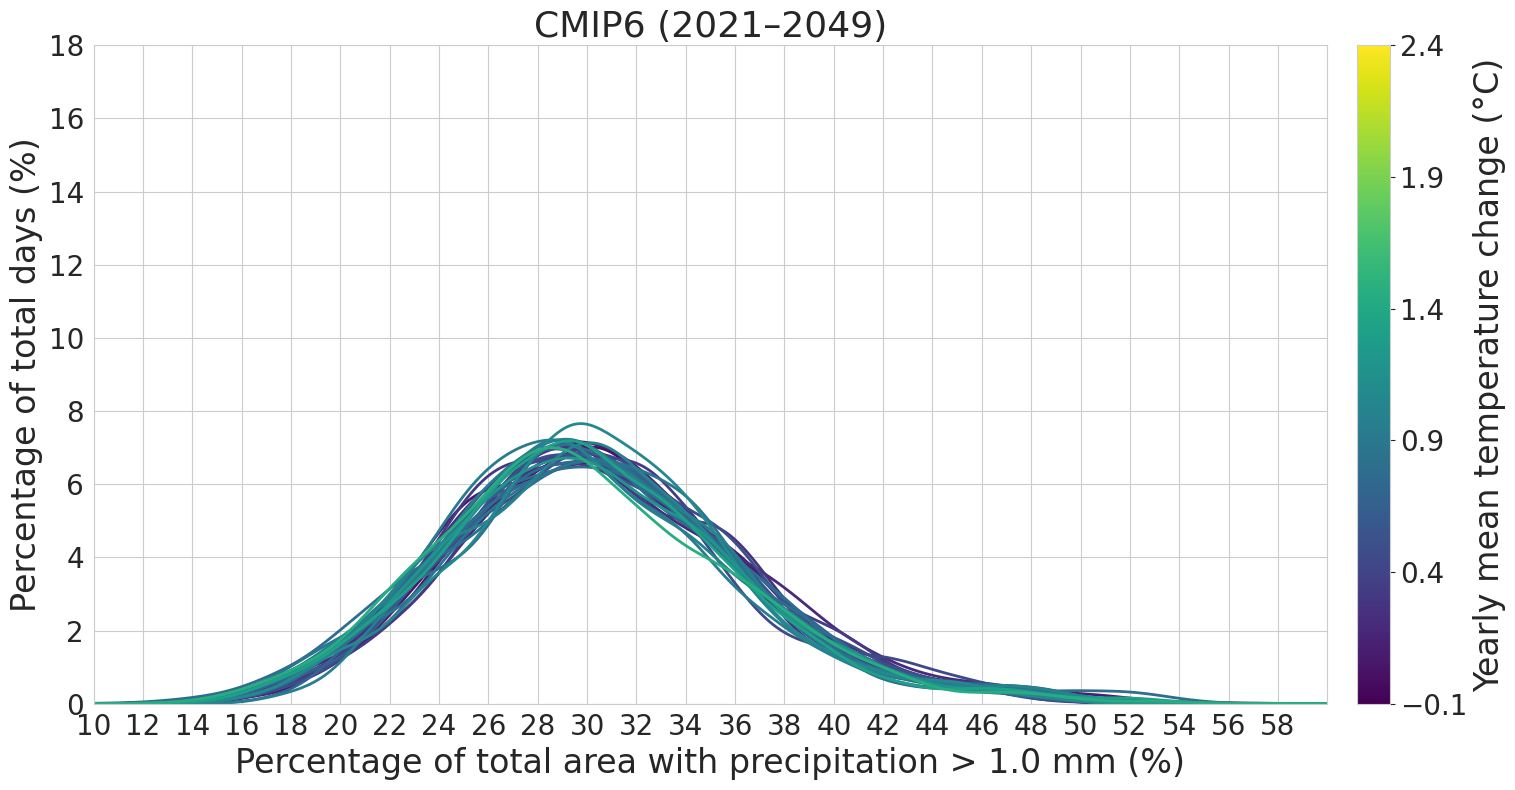

In [12]:
# ── plot: one line per year (all models pooled), coloured by the multi-model mean land warming since REF_YEAR ──
dT_all = np.array([l['dT'] for l in lines])
vmin, vmax = CBAR_RANGE if CBAR_RANGE is not None else (np.floor(dT_all.min() * 10) / 10, np.ceil(dT_all.max() * 10) / 10)
cmap = plt.get_cmap('viridis')
norm = plt.Normalize(vmin=vmin, vmax=vmax)

order = np.argsort(dT_all)                     # warmest lines drawn last (on top)
segments = [np.column_stack([X_GRID, lines[i]['curve'] * bin_width * 100]) for i in order]   # density -> % of days per bin

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")
ax.add_collection(LineCollection(segments, colors=cmap(norm(dT_all[order])), linewidths=LINE_WIDTH))

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=np.linspace(vmin, vmax, 6))
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)


ax.set_xticks(np.arange(xmin, xmax, 2))
ax.set_ylim(0, 18)
ax.set_xlim(xmin, xmax)
ax.set_xlabel(f'Percentage of total area with precipitation > {THRESHOLD} mm (%)', fontsize=24)
ax.set_ylabel('Percentage of total days (%)', fontsize=24)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.set_title(f'CMIP6 ({years[0]}–{years[-1]})', fontsize=26)
plt.tight_layout()
os.makedirs(os.path.dirname(OUT_FIG), exist_ok=True)
plt.savefig(OUT_FIG, format='pdf', bbox_inches='tight')
plt.show()
